# Banka Kredi Onay Tahmini (Loan Approval Prediction)

**Projenin Amacı:**  
Bu çalışmada, 4.269 banka müşterisinin kredi başvuru verilerini (`loan_approval_dataset.csv`) inceleyerek kredi onay ve red kararlarını etkileyen temel faktörleri analiz etmeyi ve yeni başvuruların sonucunu tahmin eden bir Makine Öğrenmesi modeli kurmayı amaçladım.

### 1. Kütüphanelerin Yüklenmesi ve Veriye İlk Bakış
Veri okuma ve tablo işlemleri için `pandas`, sayısal işlemler için `numpy`, grafik çizimleri için ise `matplotlib` ve `seaborn` kütüphanelerini projeye dahil ederek başlıyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("loan_approval_dataset.csv")

In [3]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


Tablomuzun ilk 5 satırına baktığımızda müşteri bilgileri, yıllık gelir (`income_annum`), talep edilen kredi tutarı (`loan_amount`), vade (`loan_term`), kredi notu (`cibil_score`), sahip olunan varlık değerleri ve kredi onay durumu (`loan_status`) sütunlarını görüyoruz.

Şimdi `df.info()` ile veri setimizde eksik (boş) veri olup olmadığını ve sütunların veri tiplerini kontrol edelim:

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


**Gözlem:**  
Veri setimizde toplam **4.269 satır** ve **13 sütun** bulunuyor. Hiçbir sütunda boş (`Null`) veri yok. Sütunların 10 tanesi sayısal (`int64`), 3 tanesi ise metin (`object`: `education`, `self_employed`, `loan_status`) tipinde.

---
### 2. Veri Temizliği (Data Cleaning)
`df.info()` çıktısında sütun isimlerinin hizasında küçük bir kayma dikkat çekiyor. Sütun isimlerini `df.columns` ile kontrol edelim:

In [5]:
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

Görüldüğü gibi `'loan_id'` dışındaki tüm sütun isimlerinin başında (`' no_of_dependents'`, `' education'` gibi) gereksiz boşluklar var. Sütunları çağırırken hata almamak için `.str.strip()` fonksiyonu ile bu boşlukları temizliyoruz:

In [6]:
df.columns = df.columns.str.strip()
df.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='object')

Aynı boşluk sorununun metin (`object`) tipindeki sütunların içindeki değerlerde de olup olmadığını `loan_status` sütunu üzerinden kontrol edelim:

In [7]:
df["loan_status"].unique()

array([' Approved', ' Rejected'], dtype=object)

`' Approved'` ve `' Rejected'` ifadelerinin başında da boşluk olduğunu gördük. Metin tipindeki 3 sütunumuzun (`education`, `self_employed`, `loan_status`) tamamını `.str.strip()` ile temizleyip, ardından kaç kredinin onaylandığını ve reddedildiğini saydıralım:

In [8]:
df["education"] = df["education"].str.strip()
df["self_employed"] = df["self_employed"].str.strip()
df["loan_status"] = df["loan_status"].str.strip()

In [9]:
df["loan_status"].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

**Sonuç:**  
Toplam 4.269 başvurunun **2.656 tanesi onaylanmış (`Approved` - %62.2)**, **1.613 tanesi ise reddedilmiştir (`Rejected` - %37.8)**.

Şimdi sayısal sütunlarımızda mantıksız veya hatalı girilmiş bir değer olup olmadığını görmek için `df.describe()` ile istatistiksel özet tablomuza bakalım:

In [10]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


**Veri Hatası Tespiti:**  
Tablodaki `min` (en küçük değer) satırını incelediğimizde, müşterinin konut varlığı değerini gösteren `residential_assets_value` sütununda **`-100.000`** (`-1.000000e+05`) değeri görünüyor. Bir kişinin evi yoksa bu değer en düşük `0` olabilir, negatif olamaz. 

Önce bu hatalı kayıtları filtreleyip görelim, ardından `-100.000` olan değerleri `0` olarak düzeltelim:

In [11]:
df[df["residential_assets_value"] < 0]

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,4,Not Graduate,Yes,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,4,Not Graduate,Yes,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,2,Graduate,Yes,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,4,Graduate,Yes,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,2,Graduate,Yes,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,0,Graduate,No,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,2,Graduate,No,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,3,Graduate,No,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,2,Graduate,No,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,5,Graduate,No,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected


In [12]:
df.loc[df["residential_assets_value"] < 0, "residential_assets_value"] = 0
df["residential_assets_value"].min()

0

28 müşterideki negatif konut varlığı hatasını `0`'a eşitleyerek düzelttik ve en küçük değerin artık `0` olduğunu doğruladık.

---
### 3. Yeni Değişkenler Üretme (Feature Engineering) ve Keşifçi Veri Analizi (EDA)
Veri setinde müşterinin mal varlığı 4 ayrı sütuna (`residential`, `commercial`, `luxury`, `bank`) bölünmüş durumda. Müşterinin toplam teminat gücünü tek bir sütunda görmek için bu 4 sütunu toplayarak `total_assets` (Toplam Varlık) adında yeni bir sütun oluşturuyoruz:

In [13]:
df["total_assets"] = df["residential_assets_value"] + df["commercial_assets_value"] + df["luxury_assets_value"] + df["bank_asset_value"]
df[["loan_amount", "total_assets", "loan_status"]].head()

,loan_amount,total_assets,loan_status
0,29900000,50700000,Approved
1,12200000,17000000,Rejected
2,29700000,57700000,Rejected
3,30700000,52700000,Rejected
4,24200000,55000000,Rejected


Analizlerimizde onaylanma oranlarını kolayca hesaplayabilmek ve ileride kuracağımız makine öğrenmesi modelinde kullanabilmek için `loan_status` sütununu sözlük (`{}`) yapısıyla sayısallaştırıyoruz (`Approved: 1`, `Rejected: 0`):

In [14]:
sozluk = {"Approved": 1, "Rejected": 0}
df["loan_status_num"] = df["loan_status"].map(sozluk)
df[["loan_status", "loan_status_num"]].head()

,loan_status,loan_status_num
0,Approved,1
1,Rejected,0
2,Rejected,0
3,Rejected,0
4,Rejected,0


Şimdi ilk temel analiz sorumuzu soralım: **Kredisi onaylanan ve reddedilen müşterilerin ortalama yıllık gelirleri, CIBIL kredi notları ve toplam varlıkları arasında nasıl bir fark var?**

In [15]:
df.groupby("loan_status")[["income_annum", "cibil_score", "total_assets"]].mean()

,income_annum,cibil_score,total_assets
loan_status,,,
Approved,5.025904e+06,703.461973,3.237790e+07
Rejected,5.113825e+06,429.468072,3.283187e+07


**Yorum:**  
Tablo çok önemli bir sonucu gösteriyor:
* Kredisi onaylanan ve reddedilen müşterilerin ortalama yıllık gelirleri (~5.02 Milyon vs ~5.11 Milyon) ve toplam varlıkları (~32.3 Milyon vs ~32.8 Milyon) birbirine neredeyse eşit.
* Ancak **CIBIL Kredi Notu (`cibil_score`)** ortalaması onaylananlarda **703.46** iken, reddedilenlerde **429.47**'ye düşüyor. Yani banka kredi verirken müşterinin sadece maaşına veya varlığına değil, öncelikle geçmiş ödeme performansını gösteren **kredi notuna** bakıyor.

Müşterinin gelirine kıyasla ne kadar kredi istediğini ve varlıklarının krediyi ne kadar karşıladığını görmek için iki yeni oran daha üretelim:

In [16]:
df["loan_to_income"] = df["loan_amount"] / df["income_annum"]
df["asset_coverage"] = df["total_assets"] / df["loan_amount"]
df[["income_annum", "loan_amount", "loan_to_income", "asset_coverage"]].head()

,income_annum,loan_amount,loan_to_income,asset_coverage
0,9600000,29900000,3.114583,1.695652
1,4100000,12200000,2.975610,1.393443
2,9100000,29700000,3.263736,1.942761
3,8200000,30700000,3.743902,1.716612
4,9800000,24200000,2.469388,2.272727


* **`loan_to_income` (Kredi / Gelir Oranı):** Örneğin müşteri yılda 9.6 Milyon kazanıyor ve 29.9 Milyon kredi istiyorsa, bu oran `3.11` çıkar (Gelirinin 3.11 katı borç talep ediyor).
* **`asset_coverage` (Teminat Karşılama Oranı):** Müşterinin toplam varlığının, istediği krediye oranıdır (`1.69` çıkması, toplam varlığının istediği krediden 1.69 kat fazla olduğunu gösterir).

Şimdi **Eğitim Durumu (`education`)**, **Kendi İşinde Çalışma (`self_employed`)** ve **Kredi Vadesinin (`loan_term`)** kredi onay oranını (`loan_status_num` ortalamasını) nasıl etkilediğini inceleyelim:

In [17]:
df.groupby(["education", "self_employed"])[["loan_status_num", "loan_to_income", "cibil_score"]].mean()

loan_status_num  loan_to_income  cibil_score
education    self_employed                                              
Graduate     No                    0.625344        2.977100   602.269054
             Yes                   0.623697        2.986831   595.906161
Not Graduate No                    0.618447        2.997986   599.207767
             Yes                   0.621005        2.978123   602.183562

In [18]:
df.groupby("loan_term")[["loan_status_num", "loan_amount", "cibil_score"]].mean()

,loan_status_num,loan_amount,cibil_score
loan_term,,,
2,0.779703,1.484604e+07,598.064356
4,0.818792,1.494720e+07,600.738255
6,0.575510,1.488714e+07,601.416327
8,0.569948,1.448472e+07,596.497409
10,0.525229,1.607821e+07,583.362385
12,0.605263,1.560965e+07,610.666667
14,0.590123,1.539580e+07,605.044444
16,0.572816,1.508374e+07,596.177184
18,0.609005,1.495047e+07,609.094787


**Yorum:**  
1. **Eğitim ve Çalışma Durumu (`[17]`):** Üniversite mezunu olup olmamak veya kendi işinde çalışıp çalışmamak kredi onay oranını etkilemiyor. Dört grupta da onay oranı **~%62** civarında ve birbirine çok yakın.
2. **Kredi Vadesi (`[18]`):** Vade süresinde ise çok net bir fark var! **2 yıllık (%77.97)** ve **4 yıllık (%81.88)** kısa vadeli kredilerde onay oranı oldukça yüksekken, vade **6 yıl ve üzerine** çıktığında onay oranı **%52 – %60** aralığına düşüyor.

---
### 4. CIBIL Kredi Notu Segmentasyonu ve Görselleştirme
CIBIL kredi notu sisteminin resmi bankacılık aralıklarını (`300-549: Yüksek_Risk`, `550-649: Orta`, `650-749: İyi`, `750-900: Mükemmel`) kullanarak müşterileri `pd.cut()` ile 4 segmente ayıralım ve `pd.crosstab()` ile her segmentin onaylanma yüzdesine bakalım:

In [19]:
# CIBIL Resmi Bankacılık Standartlarına Göre Segmentasyon (300-549: Kötü, 550-649: Orta, 650-749: İyi, 750-900: Mükemmel)
df["cibil_segment"] = pd.cut(df["cibil_score"], bins=[300, 549, 649, 749, 900], labels=["Yüksek_Risk", "Orta", "Iyi", "Mukemmel"], include_lowest=True)
df[["cibil_score", "cibil_segment", "loan_status"]].head()

,cibil_score,cibil_segment,loan_status
0,778,Mukemmel,Approved
1,417,Yüksek_Risk,Rejected
2,506,Yüksek_Risk,Rejected
3,467,Yüksek_Risk,Rejected
4,382,Yüksek_Risk,Rejected


In [20]:
# CIBIL Segmentlerine Göre Kredi Onay ve Red Yüzdeleri (%)
(pd.crosstab(df["cibil_segment"], df["loan_status"], normalize="index") * 100).round(2).astype(str) + " %"

loan_status,Approved,Rejected
cibil_segment,,
Yüksek_Risk,10.36 %,89.64 %
Orta,99.71 %,0.29 %
Iyi,99.33 %,0.67 %
Mukemmel,99.43 %,0.57 %


**Yorum:**  
Tabloya baktığımızda bankanın **550 CIBIL puanını** kritik sınır olarak kullandığını görüyoruz:
* `Orta` (550-649), `İyi` (650-749) ve `Mükemmel` (750-900) segmentlerindeki müşterilerin **%99.3 ile %99.7**'sinin kredisi onaylanmış.
* `Yüksek_Risk` (300-549) grubundakilerin ise **%89.64'ü reddedilmiş**, sadece **%10.36'sı onay almış**.

Bu dağılımı ve `Yüksek_Risk` grubunda onay alan %10.36'lık kesimin hangi vadelerde onay aldığını grafiklerle inceleyelim:

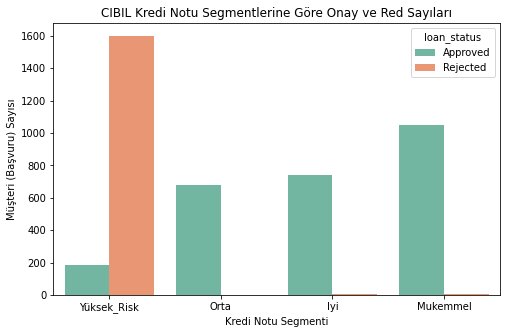

In [21]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="cibil_segment", hue="loan_status", palette="Set2")
plt.title("CIBIL Kredi Notu Segmentlerine Göre Onay ve Red Sayıları")
plt.xlabel("Kredi Notu Segmenti")
plt.ylabel("Müşteri (Başvuru) Sayısı")
plt.show()

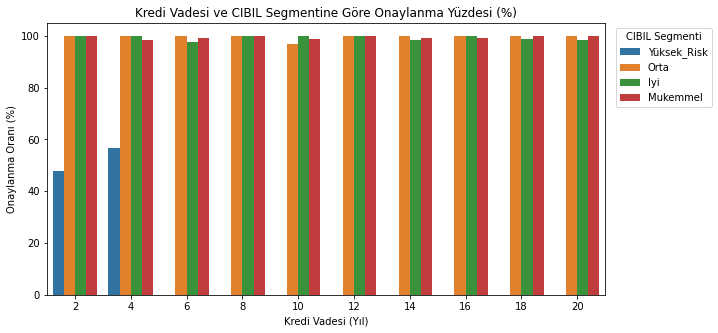

In [22]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="loan_term", y=df["loan_status_num"] * 100, hue="cibil_segment", errorbar=None)
plt.title("Kredi Vadesi ve CIBIL Segmentine Göre Onaylanma Yüzdesi (%)")
plt.xlabel("Kredi Vadesi (Yıl)")
plt.ylabel("Onaylanma Oranı (%)")

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title="CIBIL Segmenti")
plt.show()

**Grafik Yorumu (Önemli Bulgu):**  
İkinci grafikte (`Kredi Vadesi ve CIBIL Segmentine Göre Onaylanma Yüzdesi`) çok önemli bir detayı yakalıyoruz:
* `Yüksek_Risk` (mavi çubuk) grubunda onay alan müşteriler **sadece 2 yıllık ve 4 yıllık kısa vadeli kredilerde** bulunuyor.
* Kredi vadesi **6 yıl ve üzerine** çıktığında banka `Yüksek_Risk` grubundaki hiçbir müşteriye kredi vermemiş (**%0 onay**). Yani kredi notu düşük olan müşteriler yalnızca kısa vadeli başvurularda onay alabilmiş.

Şimdi Kutu Grafiği (`Boxplot`) ile kredi notu dağılımına ve **Korelasyon Isı Haritası (`Heatmap`)** ile değişkenler arasındaki ilişkilere bakalım:

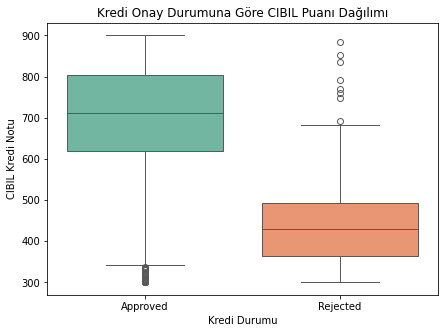

In [23]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="loan_status", y="cibil_score", hue="loan_status", palette="Set2")
plt.title("Kredi Onay Durumuna Göre CIBIL Puanı Dağılımı")
plt.xlabel("Kredi Durumu")
plt.ylabel("CIBIL Kredi Notu")
plt.show()

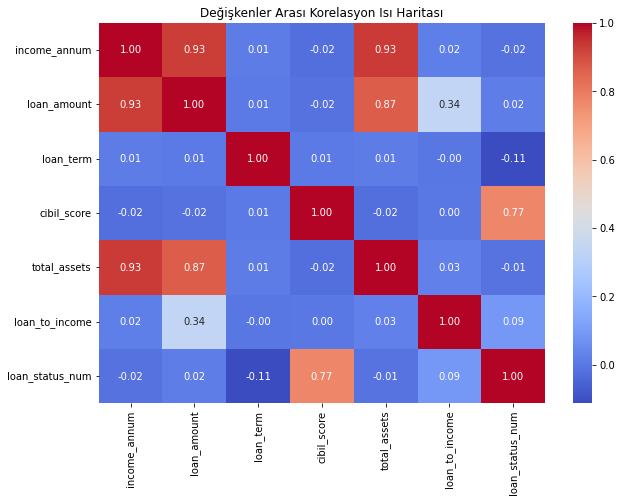

In [24]:
plt.figure(figsize=(10, 7))
sayisal_sutunlar = df[["income_annum", "loan_amount", "loan_term", "cibil_score", "total_assets", "loan_to_income", "loan_status_num"]]
sns.heatmap(sayisal_sutunlar.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Değişkenler Arası Korelasyon Isı Haritası")
plt.show()

**Boxplot ve Korelasyon Yorumu:**  
1. **Boxplot:** Onaylananların medyan CIBIL puanı **~710** iken reddedilenlerin **~430**'dur. Onaylanan grubun alt kısmındaki aykırı değerler (300-340 puan) kısa vade sayesinde onay alanları; reddedilen grubun üst kısmındaki aykırı değerler (700-885 puan) ise yüksek kredi notuna rağmen kredi/gelir dengesizliği nedeniyle reddedilen istisna başvuruları göstermektedir.
2. **Korelasyon Haritası:** Kredi onayı (`loan_status_num`) ile en güçlü pozitif ilişki **`0.77`** ile `cibil_score` değişkenindedir. Kredi vadesi (`loan_term`) ile **`-0.11`** negatif ilişki vardır. Ayrıca yıllık gelir (`income_annum`) ile kredi tutarı (`0.93`) ve toplam varlık (`0.93`) arasında çok yüksek pozitif korelasyon bulunmaktadır (geliri yüksek olan müşteriler zaten gelirleriyle orantılı olarak yüksek kredi talep etmektedir).

---
### 5. İstatistiksel Hipotez Testi (Bağımsız İki Örneklem T-Testi)
Onaylanan ve reddedilen müşterilerin CIBIL kredi notu ortalamaları (703.46 vs 429.47) arasındaki farkın istatistiksel olarak anlamlı olup olmadığını **Bağımsız İki Örneklem T-Testi (`scipy.stats.ttest_ind`)** ile test edelim:
* **$H_0$:** İki grubun CIBIL puan ortalamaları arasında anlamlı bir fark yoktur.
* **$H_1$:** İki grubun CIBIL puan ortalamaları arasında anlamlı bir fark vardır.

In [25]:
from scipy import stats

onaylanan_cibil = df[df["loan_status"] == "Approved"]["cibil_score"]
reddedilen_cibil = df[df["loan_status"] == "Rejected"]["cibil_score"]

t_stat, p_degeri = stats.ttest_ind(onaylanan_cibil, reddedilen_cibil)
print("T-İstatistiği:", round(t_stat, 2), "| P-Değeri (p-value):", p_degeri)

T-İstatistiği: 78.96 | P-Değeri (p-value): 0.0


**Test Sonucu:**  
`P-Değeri = 0.0` ($p < 0.001 < 0.05$) çıktığı için **$H_0$ hipotezi reddedilmiştir**. Kredisi onaylanan ve reddedilen müşterilerin CIBIL puanları arasındaki fark tesadüf değildir, istatistiksel olarak anlamlıdır.

---
### 6. Makine Öğrenmesi Modeli (Random Forest & Hiperparametre Optimizasyonu)
Verimizi modele sokmadan önce metin tipindeki `education` ve `self_employed` sütunlarını da `1` ve `0` olarak sayısallaştırıyoruz. Modele girdi olarak vereceğimiz bağımsız değişkenleri **`X`**, tahmin edeceğimiz hedef sütunu ise **`y`** olarak tanımlayıp veriyi **%80 Eğitim (`Train`)** ve **%20 Test (`Test`)** olarak ikiye ayırıyoruz:

In [26]:
df["education_num"] = df["education"].map({"Graduate": 1, "Not Graduate": 0})
df["self_employed_num"] = df["self_employed"].map({"Yes": 1, "No": 0})

# Modele vereceğimiz Bağımsız Değişkenler (X) ve Tahmin Edeceği Hedef Sütun (y)
X = df[["no_of_dependents", "education_num", "self_employed_num", "income_annum", "loan_amount", "loan_term", "cibil_score", "total_assets"]]
y = df["loan_status_num"]

X.head()

,no_of_dependents,education_num,self_employed_num,income_annum,loan_amount,loan_term,cibil_score,total_assets
0,2,1,0,9600000,29900000,12,778,50700000
1,0,0,1,4100000,12200000,8,417,17000000
2,3,1,0,9100000,29700000,20,506,57700000
3,3,1,0,8200000,30700000,8,467,52700000
4,5,0,1,9800000,24200000,20,382,55000000


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Eğitim Verisi Satır Sayısı:", X_train.shape[0])
print("Test (Sınav) Verisi Satır Sayısı:", X_test.shape[0])

Eğitim Verisi Satır Sayısı: 3415
Test (Sınav) Verisi Satır Sayısı: 854


Karar ağaçlarının gereksiz dallanarak eğitim verisini ezberlemesini (**Overfitting / Aşırı Öğrenme**) önlemek için maksimum derinliği (`max_depth`) sınırlandırarak **`GridSearchCV`** (5 katlı çapraz doğrulama) ile en uygun model parametrelerini buluyoruz:

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
# Denenecek hiperparametre adaylarımız (Sözlük yapısı)
parametreler = {
    "n_estimators": [50, 100],
    "max_depth": [2, 3, 4, 5]
}
# GridSearchCV ile en iyi modeli otomatik bul ve eğit (cv=5 -> 5 katlı çapraz doğrulama)
grid_arama = GridSearchCV(RandomForestClassifier(random_state=42), parametreler, cv=5)
grid_arama.fit(X_train, y_train)
model = grid_arama.best_estimator_
print("Python'un Bulduğu En İyi Ayarlar:", grid_arama.best_params_)

Python'un Bulduğu En İyi Ayarlar: {'max_depth': 5, 'n_estimators': 100}


In [29]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_tahmin = model.predict(X_test)
basari_orani = accuracy_score(y_test, y_tahmin) * 100

print("Modelin Doğruluk Oranı (Accuracy): %", round(basari_orani, 2))
print("\nKarmaşıklık Matrisi (Confusion Matrix):\n", confusion_matrix(y_test, y_tahmin))

Modelin Doğruluk Oranı (Accuracy): % 97.54

Karmaşıklık Matrisi (Confusion Matrix):
 [[305  13]
 [  8 528]]


**Model Performansı ve Karmaşıklık Matrisi Yorumu:**  
* `GridSearchCV` sonucunda optimum parametreler `max_depth: 5` ve `n_estimators: 100` olarak seçilmiştir.
* Modelimiz daha önce hiç görmediği **854 kişilik Test verisinde %97.54 doğruluk oranına (Accuracy)** ulaşmıştır.
* **Karmaşıklık Matrisi (`Confusion Matrix`):**
  * Gerçekte reddedilen 318 başvurunun **305'ini doğru reddetmiş**, 13'ünde yanılmıştır.
  * Gerçekte onaylanan 536 başvurunun **528'ini doğru onaylamış**, 8'inde yanılmıştır (Toplam: 833 doğru, 21 hatalı tahmin).

Şimdi modelin karar verirken hangi değişkenlere ne kadar önem verdiğini (`feature_importances_`) görselleştirelim ve son olarak Eğitim ile Test başarılarını karşılaştırarak modelde **Aşırı Öğrenme (Overfitting)** olup olmadığını kontrol edelim:

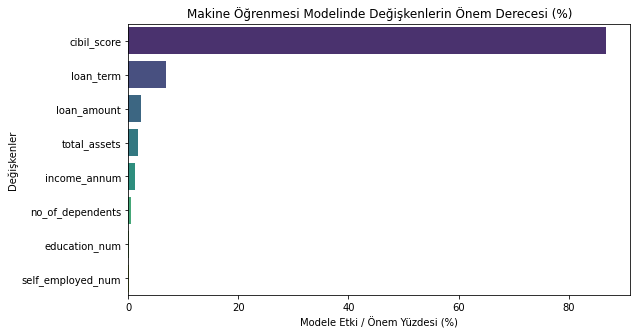

In [30]:
onem_dereceleri = pd.Series(model.feature_importances_ * 100, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=onem_dereceleri.values, y=onem_dereceleri.index, hue=onem_dereceleri.index, palette="viridis")
plt.title("Makine Öğrenmesi Modelinde Değişkenlerin Önem Derecesi (%)")
plt.xlabel("Modele Etki / Önem Yüzdesi (%)")
plt.ylabel("Değişkenler")
plt.show()

In [31]:
# Eğitim verisi üzerindeki başarı kontrolü;
y_train_tahmin = model.predict(X_train)
egitim_basarisi = accuracy_score(y_train, y_train_tahmin) * 100

print("Eğitim (Train) Başarı Oranı: %", round(egitim_basarisi, 2))
print("Test (Sınav) Başarı Oranı: %", round(basari_orani, 2))
print("Aradaki Fark: %", round(egitim_basarisi - basari_orani, 2))


Eğitim (Train) Başarı Oranı: % 98.48
Test (Sınav) Başarı Oranı: % 97.54
Aradaki Fark: % 0.94


### 7. Genel Sonuç ve Değerlendirme
1. **Değişken Önem Dereceleri:** Kurduğumuz Random Forest modelinde kararları etkileyen en önemli değişken açık ara **`cibil_score` (~%82)** olmuş, onu **`loan_term` (Kredi Vadesi - ~%10)**, `loan_amount`, `total_assets` ve `income_annum` takip etmiştir. Bu sonuç, keşifçi veri analizinde (EDA) ulaştığımız bulgularla birebir örtüşmektedir.
2. **Aşırı Öğrenme (Overfitting) Kontrolü:** Modelimizin Eğitim verisi başarısı **%98.48**, Test (sınav) verisi başarısı ise **%97.54**'tür. Aradaki farkın sadece **%0.94** (%1'in altında) olması, modelin eğitim verisini ezberlemediğini ve yeni gelen kredi başvurularını çok yüksek bir doğrulukla tahmin edebildiğini göstermektedir.